In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import cv2
import sys
import os

# Tambahkan path ke folder src agar bisa mengimpor praproses
sys.path.append('/content/drive/MyDrive/simuteh-2330511092/src')
from praproses import praproses, simpan_param
from utils_cv import baca, kontras_bercak

# Pastikan folder hasil ada untuk menyimpan JSON
path_hasil = "/content/drive/MyDrive/simuteh-2330511092/hasil"
os.makedirs(path_hasil, exist_ok=True)

# Menentukan parameter terbaik berdasarkan temuan B2-B4
param = {
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "penapis": "gaussian",
    "kernel": 5,
    "sigma": 1.0,
    "tajam_k": 0.5
}
simpan_param(param, f"{path_hasil}/param_praproses.json")

# KANAL 2 adalah Merah (R), kanal terbaik dari Bagian 2
KANAL = 2

path_data = "/content/drive/MyDrive/simuteh-2330511092/data/sintetis"
label = pd.read_csv(f"{path_data}/label.csv")
baris = []

# Loop untuk 40 citra (semua kecuali kelas 'sehat')
for _, d in label[label['kelas'] != "sehat"].iterrows():
    nama_file = d['nama_file']
    img = baca(f"{path_data}/citra/{nama_file}")
    md = cv2.imread(f"{path_data}/mask_daun/{nama_file}", 0)
    mb = cv2.imread(f"{path_data}/mask_bercak/{nama_file}", 0)

    # Proses citra menggunakan modul praproses
    out = praproses(img, param)

    # Hitung Kontras Bercak (KB) sebelum dan sesudah praproses
    kb_sebelum = kontras_bercak(img[:, :, KANAL], md, mb)
    kb_sesudah = kontras_bercak(out[:, :, KANAL], md, mb)

    # Hitung perubahan persentase
    perubahan = ((kb_sesudah - kb_sebelum) / kb_sebelum) * 100

    # PERBAIKAN: Gunakan kondisi_cahaya sesuai header di CSV[cite: 29]
    baris.append([d['kondisi_cahaya'], kb_sebelum, kb_sesudah, perubahan])

evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah", "Perubahan(%)"])
tabel_akhir = evaluasi.groupby("kondisi").mean().round(2)

print("\n--- Data untuk Mengisi Tabel 12 ---")
print(tabel_akhir)


--- Data untuk Mengisi Tabel 12 ---
                KB_sebelum  KB_sesudah  Perubahan(%)
kondisi                                             
bayangan              5.52        8.61         59.02
gelap                 9.70       15.94         70.05
kontras_rendah        3.58        4.88         37.17
normal                9.37       11.15         22.74
terang                6.49        5.89        -10.19


--- Rata-rata Simpangan Baku Daun Sehat per Kondisi (Langkah 5.3) ---
                Std_Sebelum  Std_Sesudah
Kondisi                                 
bayangan              14.39        10.25
gelap                  8.93         6.75
kontras_rendah         9.25         9.32
normal                10.83         9.21
terang                11.39        12.27


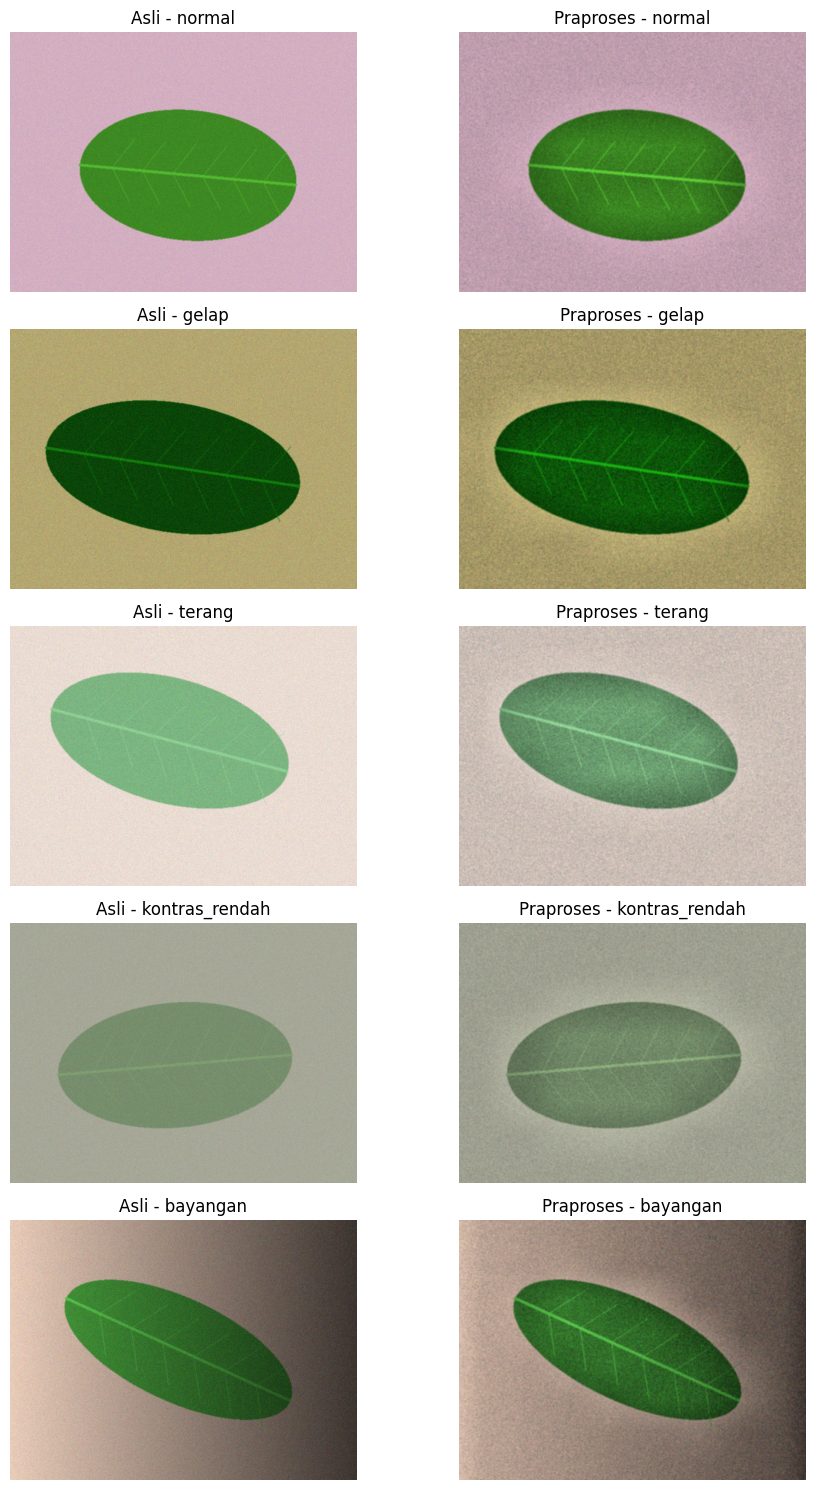

In [5]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append('/content/drive/MyDrive/simuteh-2330511092/src')
from praproses import praproses
from utils_cv import baca

# Parameter sama seperti yang digunakan di Langkah 5.2
param = {
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "penapis": "gaussian",
    "kernel": 5,
    "sigma": 1.0,
    "tajam_k": 0.5
}
KANAL = 2  # Kanal Merah (R)

path_data = "/content/drive/MyDrive/simuteh-2330511092/data/sintetis"
label = pd.read_csv(f"{path_data}/label.csv")

# Filter hanya kelas sehat (20 citra pertama, teh_001 - teh_020)
label_sehat = label[label['kelas'] == 'sehat']

hasil_std = []
contoh_visual = {}

for _, d in label_sehat.iterrows():
    nama = d['nama_file']
    kondisi = d['kondisi_cahaya']

    img = baca(f"{path_data}/citra/{nama}")
    md = cv2.imread(f"{path_data}/mask_daun/{nama}", 0)

    out = praproses(img, param)

    # Ambil nilai intensitas hanya pada area daun (mask_daun > 0)
    daun_asli = img[:, :, KANAL][md > 0]
    daun_praproses = out[:, :, KANAL][md > 0]

    # Hitung simpangan baku (menunjukkan tingkat ketidakrataan / noise)
    std_asli = daun_asli.std()
    std_praproses = daun_praproses.std()

    hasil_std.append([kondisi, std_asli, std_praproses])

    # Simpan satu sampel per kondisi untuk plot visual
    if kondisi not in contoh_visual:
        contoh_visual[kondisi] = (img, out)

df_std = pd.DataFrame(hasil_std, columns=["Kondisi", "Std_Sebelum", "Std_Sesudah"])
print("--- Rata-rata Simpangan Baku Daun Sehat per Kondisi (Langkah 5.3) ---")
print(df_std.groupby("Kondisi").mean().round(2))

# Tampilkan panel sebelum dan sesudah untuk 1 citra setiap kondisi
fig, axes = plt.subplots(len(contoh_visual), 2, figsize=(10, 15))
for i, (kondisi, (img_asli, img_out)) in enumerate(contoh_visual.items()):
    axes[i, 0].imshow(cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"Asli - {kondisi}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cv2.cvtColor(img_out, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"Praproses - {kondisi}")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

In [6]:
%cd /content/drive/MyDrive/simuteh-2330511092

/content/drive/MyDrive/simuteh-2330511092
